
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [ ]:
import pandas as pd
from pathlib import Path

folder = Path("UCI HAR Dataset")

features = pd.read_csv(
    folder / "features.txt",
    sep=r"\s+",
    header=None
)[1].tolist()

seen = {}
unique_features = []

for name in features:
    if name not in seen:
        seen[name] = 0
        unique_features.append(name)
    else:
        seen[name] += 1
        unique_features.append(f"{name}_{seen[name]}")

features = unique_features

activities = pd.read_csv(
    folder / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"]
)

data = []

for part in ["train", "test"]:
    X = pd.read_csv(
        folder / part / f"X_{part}.txt",
        sep=r"\s+",
        header=None,
        names=features
    )

    y = pd.read_csv(
        folder / part / f"y_{part}.txt",
        sep=r"\s+",
        header=None,
        names=["activity_id"]
    )

    subject = pd.read_csv(
        folder / part / f"subject_{part}.txt",
        sep=r"\s+",
        header=None,
        names=["subject"]
    )

    part_df = pd.concat([X, y, subject], axis=1)
    data.append(part_df)

df = pd.concat(data, ignore_index=True)

df = df.merge(activities, on="activity_id", how="left")

df.to_csv(
    "Human_Activity_Recognition_Using_Smartphones_Data.csv",
    index=False
)

print("Размерность:", df.shape)
print(df.head())
print("Пропущенные значения:", df.isnull().sum().sum())

Размерность: (10299, 564)
   tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  tBodyAcc-std()-X  \
0           0.288585          -0.020294          -0.132905         -0.995279   
1           0.278419          -0.016411          -0.123520         -0.998245   
2           0.279653          -0.019467          -0.113462         -0.995380   
3           0.279174          -0.026201          -0.123283         -0.996091   
4           0.276629          -0.016570          -0.115362         -0.998139   

   tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  tBodyAcc-mad()-Y  \
0         -0.983111         -0.913526         -0.995112         -0.983185   
1         -0.975300         -0.960322         -0.998807         -0.974914   
2         -0.967187         -0.978944         -0.996520         -0.963668   
3         -0.983403         -0.990675         -0.997099         -0.982750   
4         -0.980817         -0.990482         -0.998321         -0.979672   

   tBodyAcc-mad()-Z  tBodyAcc-

In [5]:
print("размерность:", df.shape)

print("\nтипы данных:")
print(df.dtypes.value_counts())

print("\nинформация о DataFrame:")
df.info()

print("\nпервые 5 строк:")
display(df.head())

print("\nКоличество пропусков:", df.isnull().sum().sum())

размерность: (10299, 564)

типы данных:
float64    561
int64        2
str          1
Name: count, dtype: int64

информация о DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 10299 entries, 0 to 10298
Columns: 564 entries, tBodyAcc-mean()-X to activity
dtypes: float64(561), int64(2), str(1)
memory usage: 44.3 MB

первые 5 строк:


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",activity_id,subject,activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,5,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,5,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,5,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,5,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,5,1,STANDING



Количество пропусков: 0



## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

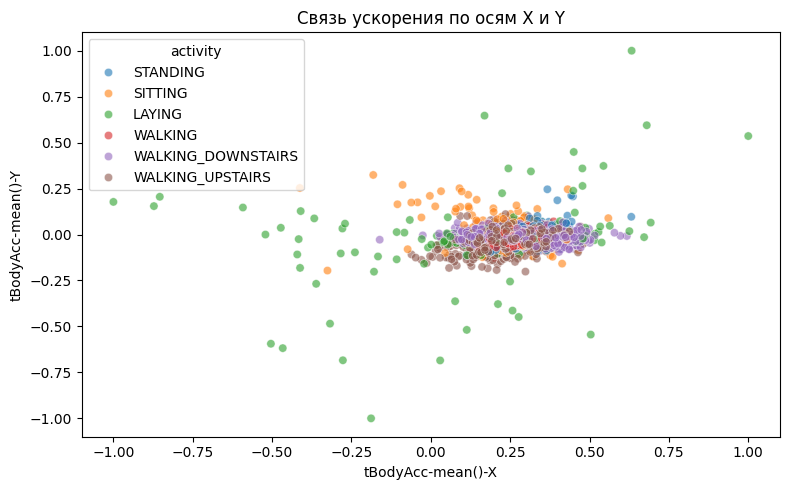

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="tBodyAcc-mean()-X",
    y="tBodyAcc-mean()-Y",
    hue="activity",
    alpha=0.6
)
plt.title("Связь ускорения по осям X и Y")
plt.tight_layout()
plt.show()

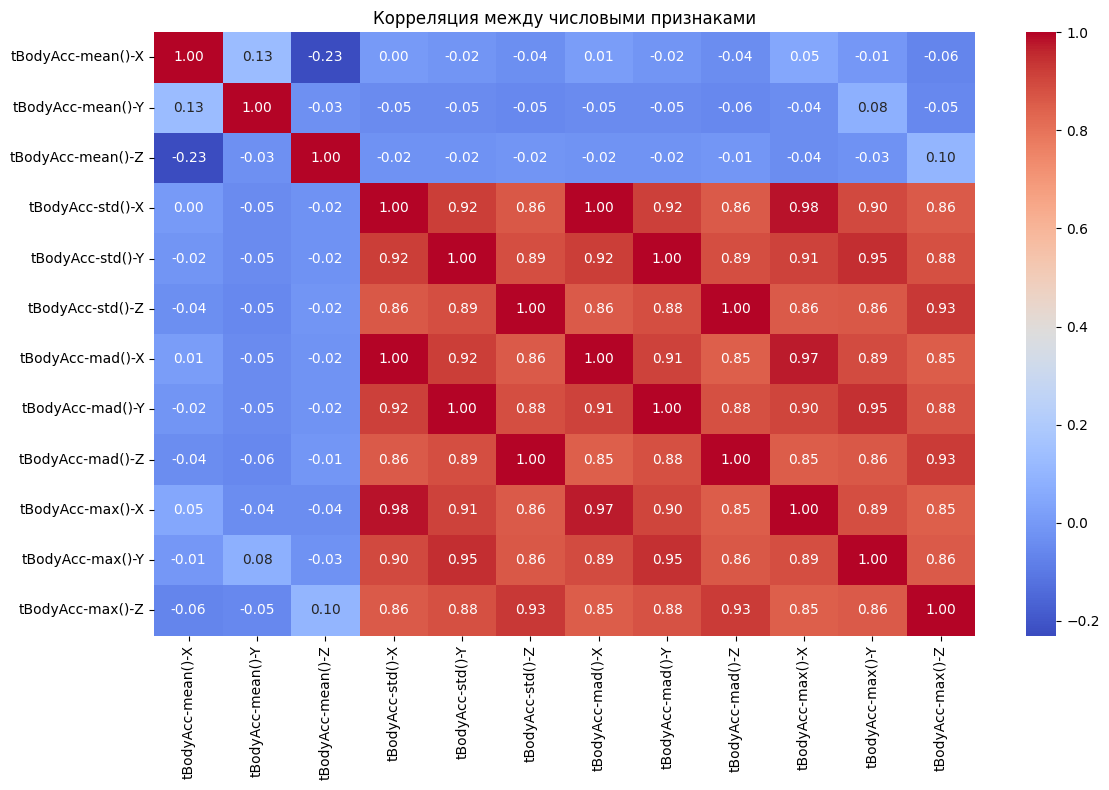

In [7]:
features_corr = df.columns[:12].tolist()

plt.figure(figsize=(12, 8))
sns.heatmap(
    df[features_corr].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Корреляция между числовыми признаками")
plt.tight_layout()
plt.show()

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_reg = df.iloc[:, :10]
y_reg = df["tBodyAcc-mean()-X"]

X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

model_reg = LinearRegression()
model_reg.fit(X_train, y_train)

pred = model_reg.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred))
print("MSE:", mean_squared_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

MAE: 2.786266952730724e-16
MSE: 8.617866583478577e-32
RMSE: 2.935620306422235e-16



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [12]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier


X = df.drop(columns=["activity", "activity_id", "subject"])
y = df["activity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

scores = cross_val_score(
    knn,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Accuracy для каждого фолда:", scores)
print("Средняя Accuracy:", scores.mean())
print("Стандартное отклонение:", scores.std())

Размер обучающей выборки: (8239, 561)
Размер тестовой выборки: (2060, 561)
Accuracy для каждого фолда: [0.95509709 0.95631068 0.95206311 0.95934466 0.95142684]
Средняя Accuracy: 0.9548484741306641
Стандартное отклонение: 0.00289418094165687



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

target = "tBodyAcc-mean()-X"

X_reg = df.drop(columns=[
    target, "activity", "activity_id", "subject"
])
y_reg = df[target]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train_reg, y_train_reg)
y_pred_reg = linear_model.predict(X_test_reg)

print("Линейная регрессия")
print("MAE:", mean_absolute_error(y_test_reg, y_pred_reg))
print("MSE:", mean_squared_error(y_test_reg, y_pred_reg))
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)))
print("R²:", r2_score(y_test_reg, y_pred_reg))

Линейная регрессия
MAE: 0.02326107490669797
MSE: 0.0015582043002541894
RMSE: 0.03947409657299568
R²: 0.6857532507151176


Логистическая регрессия
Accuracy: 1.0

Отчёт о классификации:
              precision    recall  f1-score   support

Без движения       1.00      1.00      1.00      1126
    Движение       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



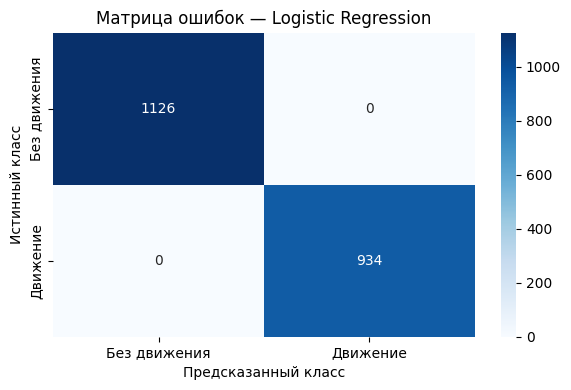

In [ ]:
X = df.drop(columns=["activity", "activity_id", "subject"])

y_binary = df["activity"].isin([
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS"
]).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

logistic_model.fit(X_train, y_train)

y_pred_log = logistic_model.predict(X_test)

print("Логистическая регрессия")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("\nОтчёт о классификации:")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=["Без движения", "Движение"]
))

cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Без движения", "Движение"],
    yticklabels=["Без движения", "Движение"]
)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Матрица ошибок — Logistic Regression")
plt.tight_layout()
plt.show()

In [16]:
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nОтчёт о классификации:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Без движения", "Движение"]
))

SVM
Accuracy: 0.9995145631067961

Отчёт о классификации:
              precision    recall  f1-score   support

Без движения       1.00      1.00      1.00      1126
    Движение       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

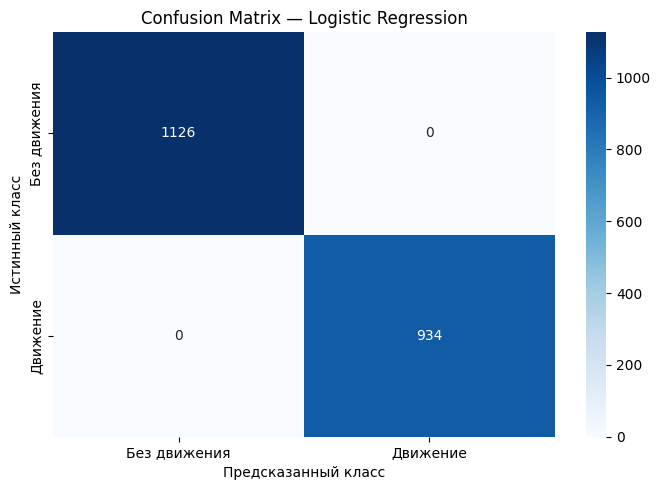

Accuracy: 1.0


In [ ]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Без движения", "Движение"],
    yticklabels=["Без движения", "Движение"]
)

plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

# 5. Точность модели
print("Accuracy:", accuracy_score(y_test, y_pred))


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

Оптимальное значение theta: 0.11956393192194933
Начальная стоимость: 0.07645277894419628
Финальная стоимость: 0.06215607455027268


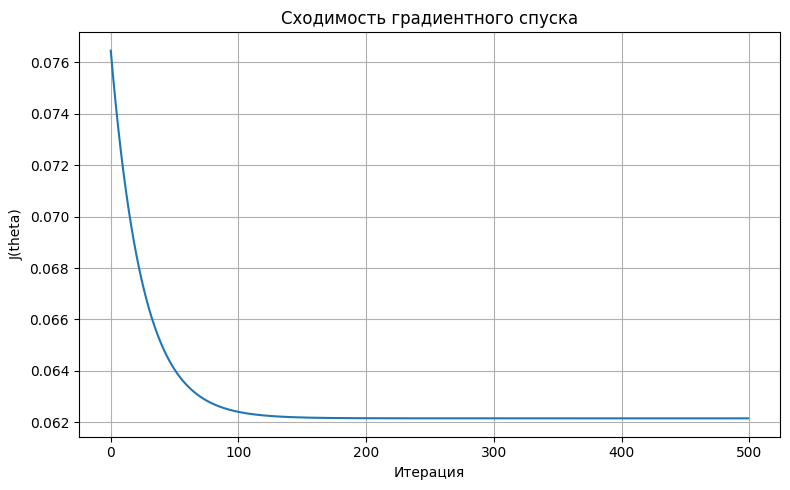

In [ ]:
data = df["tBodyAcc-mean()-X"].dropna().iloc[:100].to_numpy()

x = (data - data.mean()) / (data.std() + 1e-8)
y = data

theta = 0.0
learning_rate = 0.01
iterations = 500

cost_history = []

for i in range(iterations):
    prediction = theta * x
    error = prediction - y

    cost = np.mean(error ** 2)
    cost_history.append(cost)

    gradient = np.mean(2 * x * error)

    theta = theta - learning_rate * gradient

print("Оптимальное значение theta:", theta)
print("Начальная стоимость:", cost_history[0])
print("Финальная стоимость:", cost_history[-1])

plt.figure(figsize=(8, 5))
plt.plot(cost_history)
plt.xlabel("Итерация")
plt.ylabel("J(theta)")
plt.title("Сходимость градиентного спуска")
plt.grid(True)
plt.tight_layout()
plt.show()

## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


Random Forest Accuracy: 1.0


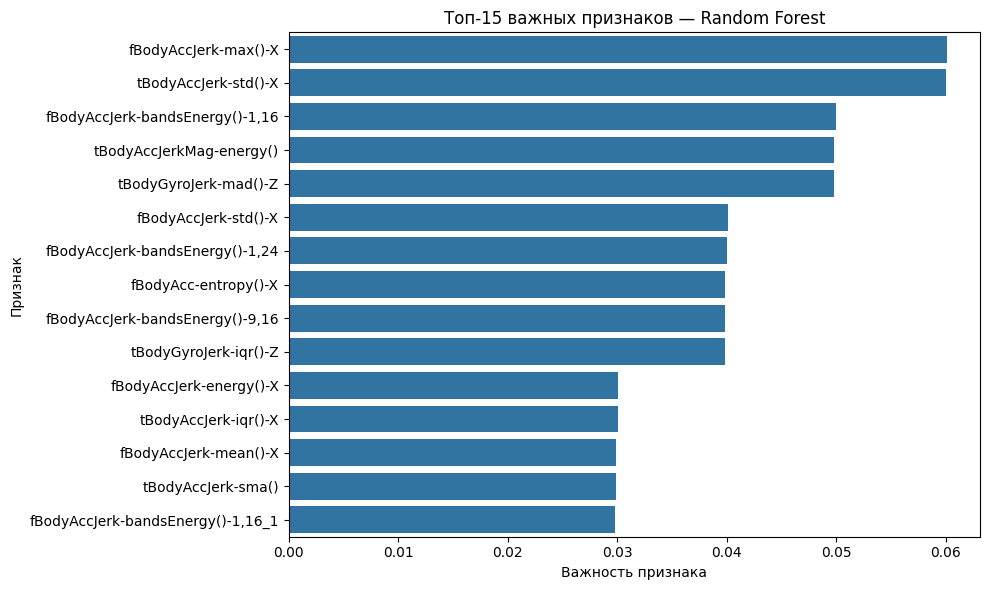

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top_features = importance.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index)
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Топ-15 важных признаков — Random Forest")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# AdaBoost
ada_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

ada_model.fit(X_train, y_train)
y_pred_ada = ada_model.predict(X_test)

# Bagging
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)
y_pred_bagging = bagging_model.predict(X_test)

results = pd.DataFrame({
    "Модель": ["Random Forest", "AdaBoost", "Bagging"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada),
        accuracy_score(y_test, y_pred_bagging)
    ]
}).sort_values("Accuracy", ascending=False)

print(results.to_string(index=False))

       Модель  Accuracy
Random Forest       1.0
     AdaBoost       1.0
      Bagging       1.0


## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [23]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

base_models = [
    (
        "random_forest",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    ),
    (
        "svm",
        make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", probability=True, random_state=42)
        )
    ),
    (
        "logistic_regression",
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        )
    )
]

stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5,
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)

y_pred_stack = stacking_model.predict(X_test)

accuracy_stack = accuracy_score(y_test, y_pred_stack)

print("Stacking Accuracy:", accuracy_stack)
print("\nОтчёт о классификации:")
print(classification_report(
    y_test,
    y_pred_stack,
    target_names=["Без движения", "Движение"]
))

Stacking Accuracy: 1.0

Отчёт о классификации:
              precision    recall  f1-score   support

Без движения       1.00      1.00      1.00      1126
    Движение       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060




## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
